This Is the EDA of music-mental-health, where we used ML to  see how music associates with some kind of mental deaseases. at the end we showed REGRESSION MODELING AND MODEL COMPARISON

In [1]:
import pandas as pd
from pathlib import Path


In [2]:
df=pd.read_csv("C:/Users/USER/Downloads/archive (1)/mxmh_survey_results.csv")
df.head()

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,...,Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,...,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,...,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,...,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.
3,8/27/2022 21:40,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,...,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve,I understand.
4,8/27/2022 21:54,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,...,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve,I understand.


In [5]:
df['Age'].max()
df['Age'].min()

np.float64(10.0)

Most respondents are in their late teens or early twenties. A single 89 year old respondent is an interesting outlier!

> The age distribution makes sense, as the survey used to collect data was advertised in discussion forums and social media sites that target this demographic. This may introduce age bias, i.e. influencing which music genres are most popular.

In [6]:
df.describe()

df.isna().sum()
df.dropna(inplace=True)
df.isna().sum()
df.isnull().sum()

Timestamp                       0
Age                             0
Primary streaming service       0
Hours per day                   0
While working                   0
Instrumentalist                 0
Composer                        0
Fav genre                       0
Exploratory                     0
Foreign languages               0
BPM                             0
Frequency [Classical]           0
Frequency [Country]             0
Frequency [EDM]                 0
Frequency [Folk]                0
Frequency [Gospel]              0
Frequency [Hip hop]             0
Frequency [Jazz]                0
Frequency [K pop]               0
Frequency [Latin]               0
Frequency [Lofi]                0
Frequency [Metal]               0
Frequency [Pop]                 0
Frequency [R&B]                 0
Frequency [Rap]                 0
Frequency [Rock]                0
Frequency [Video game music]    0
Anxiety                         0
Depression                      0
Insomnia      

Text(0, 0.5, '')

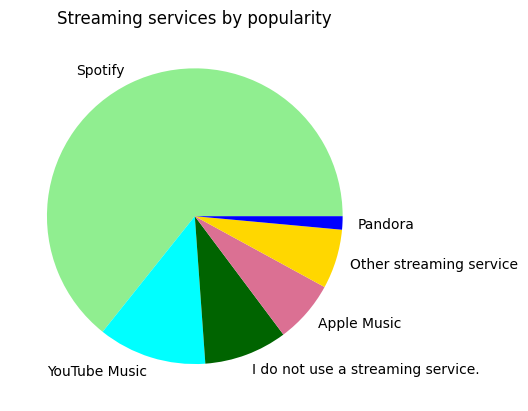

In [7]:
import matplotlib.pyplot as plt

s_colors = ['lightgreen', 'cyan', 'darkgreen', 'palevioletred', 'gold', 'blue']

services = df['Primary streaming service'].value_counts()
services.plot(kind='pie', colors = s_colors)

plt.title('Streaming services by popularity')
plt.ylabel("")


In [8]:
df['Primary streaming service'].value_counts(normalize=True)

Primary streaming service
Spotify                              0.642857
YouTube Music                        0.118506
I do not use a streaming service.    0.090909
Apple Music                          0.068182
Other streaming service              0.064935
Pandora                              0.014610
Name: proportion, dtype: float64

C:\Users\USER\AppData\Local\Temp\ipykernel_32876\3733273024.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bplot = sns.boxplot(data=df, x="Primary streaming service", y = "Age",


Text(0.5, 1.0, 'Streaming services by Age')

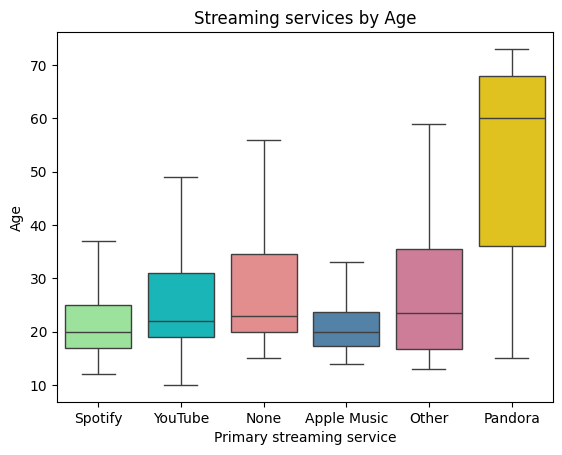

In [9]:
import seaborn as sns

s_colors2 = ['lightgreen', 'darkturquoise', 'lightcoral', 'steelblue', 'palevioletred', 'gold']

df.replace(['Other streaming service', 'I do not use a streaming service.', 'YouTube Music'],
                       ['Other', 'None', 'YouTube'], inplace=True)

bplot = sns.boxplot(data=df, x="Primary streaming service", y = "Age",
            showfliers = False,
            palette = s_colors2)

plt.title('Streaming services by Age')

In [10]:
s_df = df.groupby(['Primary streaming service'])
s_ages = []
s_ages.append(s_df['Age'].median())

s_ages

[Primary streaming service
 Apple Music    20.0
 None           23.0
 Other          23.5
 Pandora        60.0
 Spotify        20.0
 YouTube        22.0
 Name: Age, dtype: float64]

Spotify is the most popular music streaming service, accounting for 62% of all respondents. Spotify, along with Apple Music, also has a marginally younger userbase than other streaming platforms. Pandora has the oldest user base by far, with the median user age at ~60 years old.

array([[<Axes: title={'center': 'Hours per day'}>]], dtype=object)

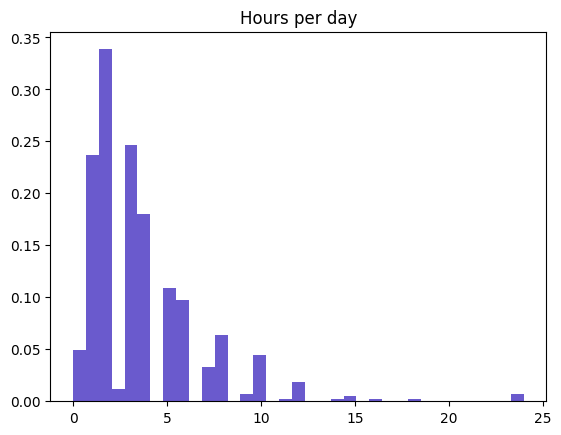

In [11]:
df.hist(['Hours per day'], bins='auto', density=True, color = 'slateblue', grid=False)

In [12]:
df['Hours per day'].value_counts().loc[lambda x : x>100]

Hours per day
2.0    131
3.0    104
Name: count, dtype: int64

The vast majority of respondents listen to music between 0-5 hours per day. After this threshold, the number of respondents that listen to music 5+ hours a day decreases almost exponentially. There are a few respondents that claim to listen to music 24 hours a day.

<Axes: ylabel='count'>

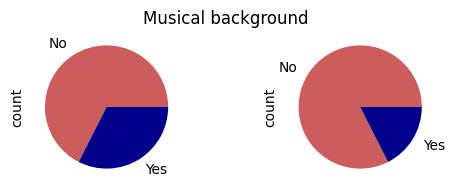

In [13]:
fig = plt.figure(figsize=(6,2))

plt.suptitle("Musical background")

ax = fig.add_subplot(121)

inst = df['Instrumentalist'].value_counts()
inst.plot(kind='pie', colors = ["indianred", "darkblue"], labeldistance = 1.2)

ax = fig.add_subplot(122)

comp = df['Composer'].value_counts()
comp.plot(kind='pie', colors = ["indianred", "darkblue"], labeldistance = 1.2)

Most respondents do not play an instrument. It is even rarer for a respondent to compose music.

In [14]:
df.replace(['No', 'Yes'],
                       [0, 1], inplace=True)

C:\Users\USER\AppData\Local\Temp\ipykernel_32876\3766805788.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(['No', 'Yes'],


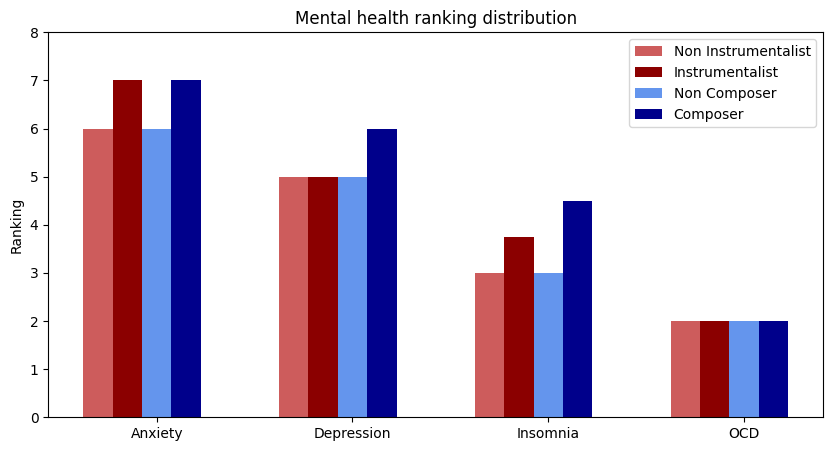

In [15]:
import numpy as np
labels = ['Anxiety', 'Depression','Insomnia', 'OCD']
x = np.arange(len(labels))
width = 0.15

fig, ax = plt.subplots(figsize=(10, 5))
mh_col=['Anxiety','Depression','Insomnia','OCD']
b1 = ax.bar(x-2*width, df[(df.Instrumentalist == 0)][mh_col].median(), width, color = 'indianred', label = "Non Instrumentalist")
b2 = ax.bar(x-width, df[(df.Instrumentalist == 1)][mh_col].median(), width, color = 'darkred', label = "Instrumentalist")
b3 = ax.bar(x, df[(df.Composer == 0)][mh_col].median(), width, color = 'cornflowerblue', label = "Non Composer")
b4 = ax.bar(x+width, df[(df.Composer == 1)][mh_col].median(), width, color = 'darkblue', label = "Composer")

ax.set_ylim([0, 8])
ax.set_ylabel('Ranking')
ax.set_title('Mental health ranking distribution')
ax.set_xticks(x, labels)
ax.legend()

plt.show()

Instrumentalists and composers have slightly higher MH rankings. However, OCD rankings are low regardless of musical background.

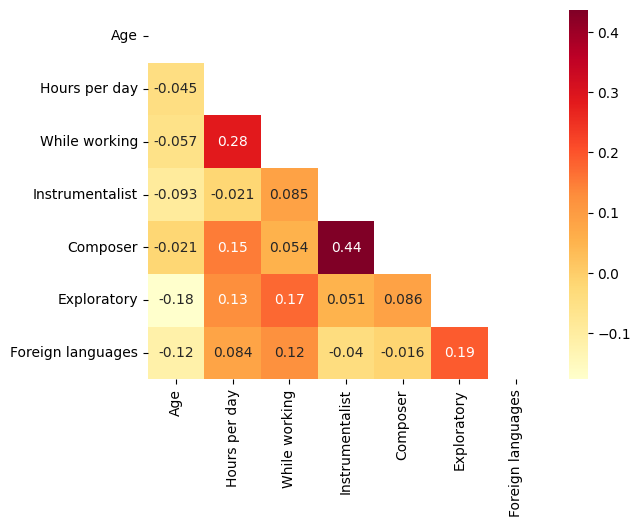

In [16]:
corr_m1 = df[['Age', 'Hours per day', 'While working', 'Instrumentalist', 'Composer', 'Exploratory', 'Foreign languages']].corr()

mask = np.triu(corr_m1)

sns.heatmap(corr_m1, annot=True, mask=mask, cmap = 'YlOrRd')
plt.show()

**Strong linear trends**

As expected, there is a a significant correlation between individuals that play music and individuals that compose music. Similarly, there is also a strong relationship between the total hours listening per day and hours listening while working.

**Weaker linear trends: exploratory respondents**

- The more hours spent listening to music, the more likely an individual actively explores new music.
- Individuals that listen to music while working are more likely to explore new music and listen to music in different languages.
- Individuals that listen to music in foreign languages are more likely to explore new music.
- Older individuals are less inclined to explore new music.

## 2. Mental health

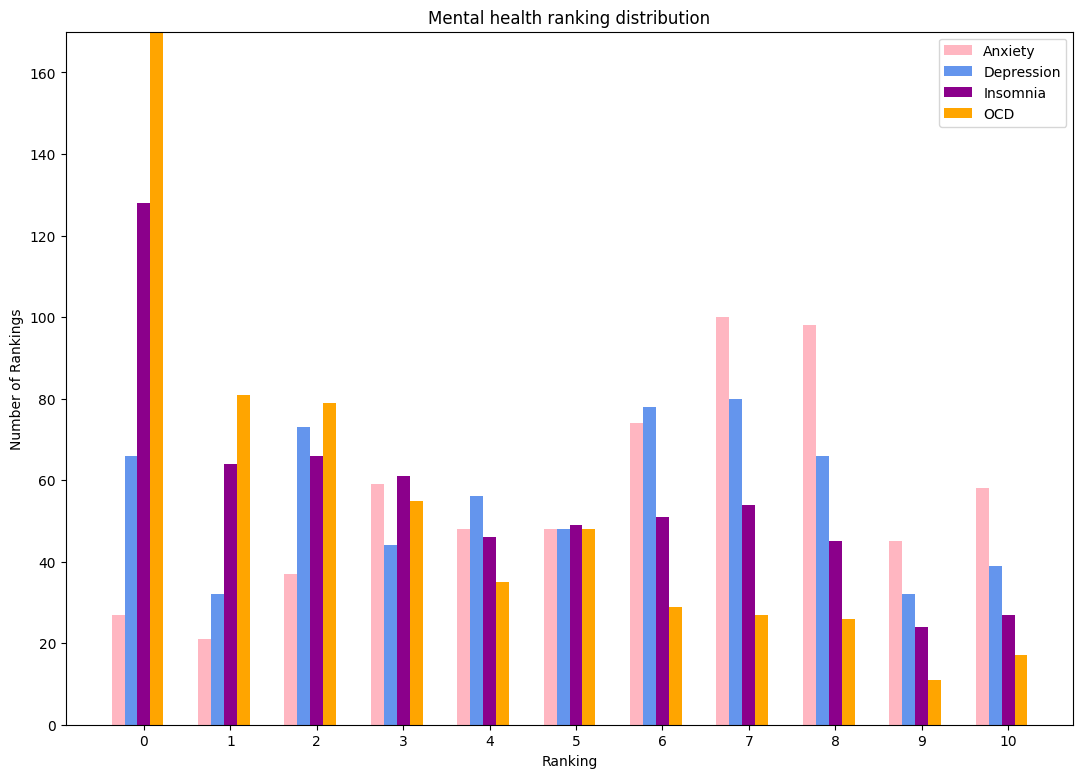

In [17]:
m_all = ["Anxiety", "Depression", "Insomnia", "OCD"]

mental_df = df[m_all]
mental_df.round(0).astype(int)

disorder_count = []
for disorder in m_all:
    x=0
    while x !=11:
        count =  (mental_df[disorder].values == x).sum()
        disorder_count.append(count)
        x +=1

labels = ['0','1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
x = np.arange(len(labels))
width = 0.15

fig, ax = plt.subplots(figsize=(13, 9))

b1 = ax.bar(x-2*width, disorder_count[0:11], width, label="Anxiety", color = 'lightpink')
b2 = ax.bar(x-width, disorder_count[11:22], width, label="Depression", color = 'cornflowerblue')
b3 = ax.bar(x, disorder_count[22:33], width, label="Insomnia", color = 'darkmagenta')
b4 = ax.bar(x+width, disorder_count[33:], width, label="OCD", color = 'orange')

ax.set_ylim([0, 170])
ax.set_ylabel('Number of Rankings')
ax.set_xlabel('Ranking')
ax.set_title('Mental health ranking distribution')
ax.set_xticks(x, labels)
ax.legend()

plt.show()

In [18]:
# get value for number of OCD rankings at 0

max(disorder_count)

np.int64(206)

In [19]:
for disorder in m_all:
    d_avg = str(round(df[disorder].mean(), 2))
    print(disorder + ' average: ' + d_avg)

Anxiety average: 5.88
Depression average: 4.89
Insomnia average: 3.8
OCD average: 2.66


Elevated rankings for depression and anxiety are very common, averaging rankings of 5 and 6 respectively. Between each ranking, popularity also seems to move in the same direction (i.e., from rankings 1 to 2, the popularity of these rankings increases for both anxiety and depression.) Interestingly (albeit concerningly), a given individual is more likely to rank depression at 10 than 0.

Insomnia is somewhat common and distributed more fairly outside of the 0 ranking. However, insomnia rankings do demonstrate a downward trend in popularity as the rankings increase.

With 0 as its mode, OCD is the least common disorder. Similarly to the insomnia rankings, as OCD rankings increase, they tend to decrease in popularity.

### Listening time & MH

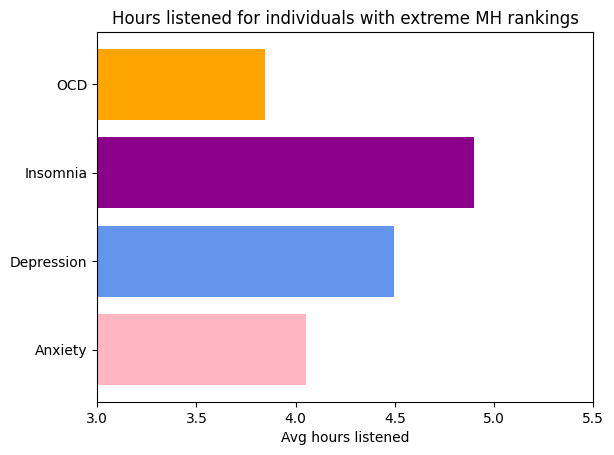

In [20]:
# compute average hours listened for respondents with extreme (9-10) MH rankings
anxiety_extreme = df.loc[df['Anxiety'] > 8, 'Hours per day'].mean()
depression_extreme = df.loc[df['Depression'] > 8, 'Hours per day'].mean()
insomnia_extreme = df.loc[df['Insomnia'] > 8, 'Hours per day'].mean()
ocd_extreme = df.loc[df['OCD'] > 8, 'Hours per day'].mean()

extreme_means = [anxiety_extreme, depression_extreme, insomnia_extreme, ocd_extreme]

plt.barh(m_all, extreme_means, color=('lightpink', 'cornflowerblue', 'darkmagenta', 'orange'))
plt.xlabel("Avg hours listened")
plt.title("Hours listened for individuals with extreme MH rankings")
plt.xlim(3,5.5)
plt.show()


An extreme MH ranking is defined as a ranking of 9 or 10. Extreme insomniacs rack up slightly more listening time compared to individuals with extreme rankings in other categories. Individuals with extreme OCD have a slightly lower listening time. However, these differences may be considered negligible.

Take note that individuals may exist in multiple extreme categories if they answered a 9 or 10 for multiple MH categories.

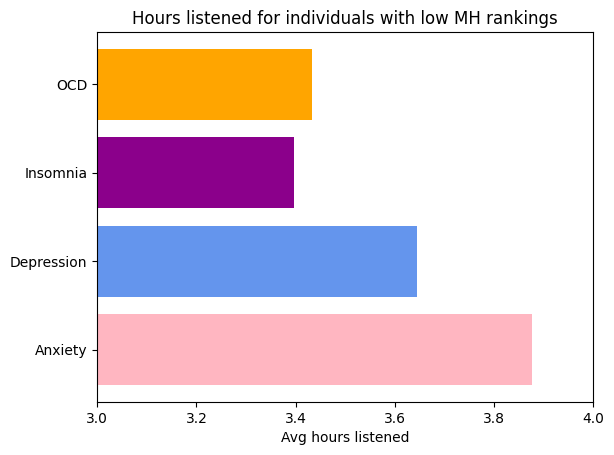

In [21]:
# compute average hours listened for respondents with low (0-2) MH rankings
anxiety_extreme2 = df.loc[df['Anxiety'] < 3, 'Hours per day'].mean()
depression_extreme2 = df.loc[df['Depression'] < 3, 'Hours per day'].mean()
insomnia_extreme2 = df.loc[df['Insomnia'] < 3, 'Hours per day'].mean()
ocd_extreme2 = df.loc[df['OCD'] < 3, 'Hours per day'].mean()

extreme_means = [anxiety_extreme2, depression_extreme2, insomnia_extreme2, ocd_extreme2]

plt.barh(m_all, extreme_means, color=('lightpink', 'cornflowerblue', 'darkmagenta', 'orange'))
plt.xlabel("Avg hours listened")
plt.title("Hours listened for individuals with low MH rankings")
plt.xlim(3,4)
plt.show()


A low MH ranking is defined as a ranking of 0, 1, or 2. Interestingly enough, individuals with low insomnia saw a noteworthy decline in average hours listened compared to their extreme counterparts. This was also the case for individuals with low depression.

Take note that individuals may exist in multiple categories if they answered a 0, 1 or 2 for multiple MH categories. Also, take note that the hours scale on this figure is different than the preceding figure.

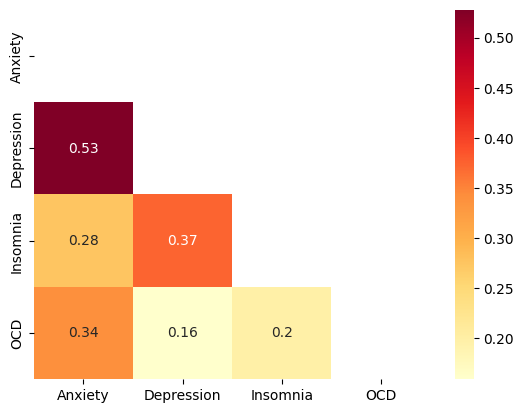

In [22]:
corr_m2 = df[['Anxiety', 'Depression', 'Insomnia', 'OCD']].corr()
mask = np.triu(corr_m2)

sns.heatmap(corr_m2, annot=True, mask=mask, cmap = 'YlOrRd')
plt.show()

All four disorders show significant overlap with each other, with depression and anxiety witnessing the strongest linear correlation. This agrees with our observations from the "Mental health ranking distribution" chart.

OCD is somewhat related to the other categories, but the correlation matrix does not imply as strong of a relationship.

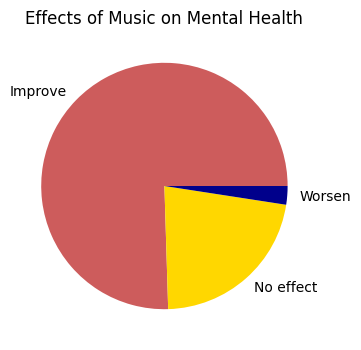

In [23]:
plt.figure(figsize=(5,4))
plt.title('Effects of Music on Mental Health')

effects = df['Music effects'].value_counts()
effects.plot(kind='pie', colors = ["indianred", "gold", "darkblue"], ylabel= '');

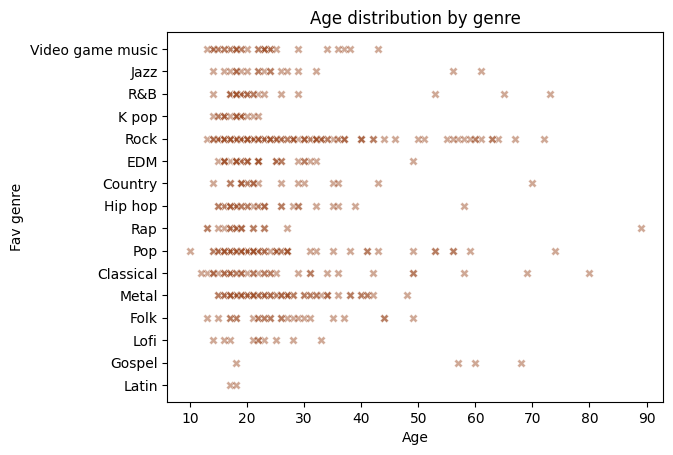

In [24]:
sns.scatterplot(data=df, y="Fav genre", x="Age", alpha = 0.5, marker = "X", color = "sienna")
plt.title('Age distribution by genre');


Rock has the most diverse range of ages. Classical and Pop listeners also have a wider range of ages compared to other genres. Some music genres, such as K pop and Lofi appear to attract a more specific and younger age group.

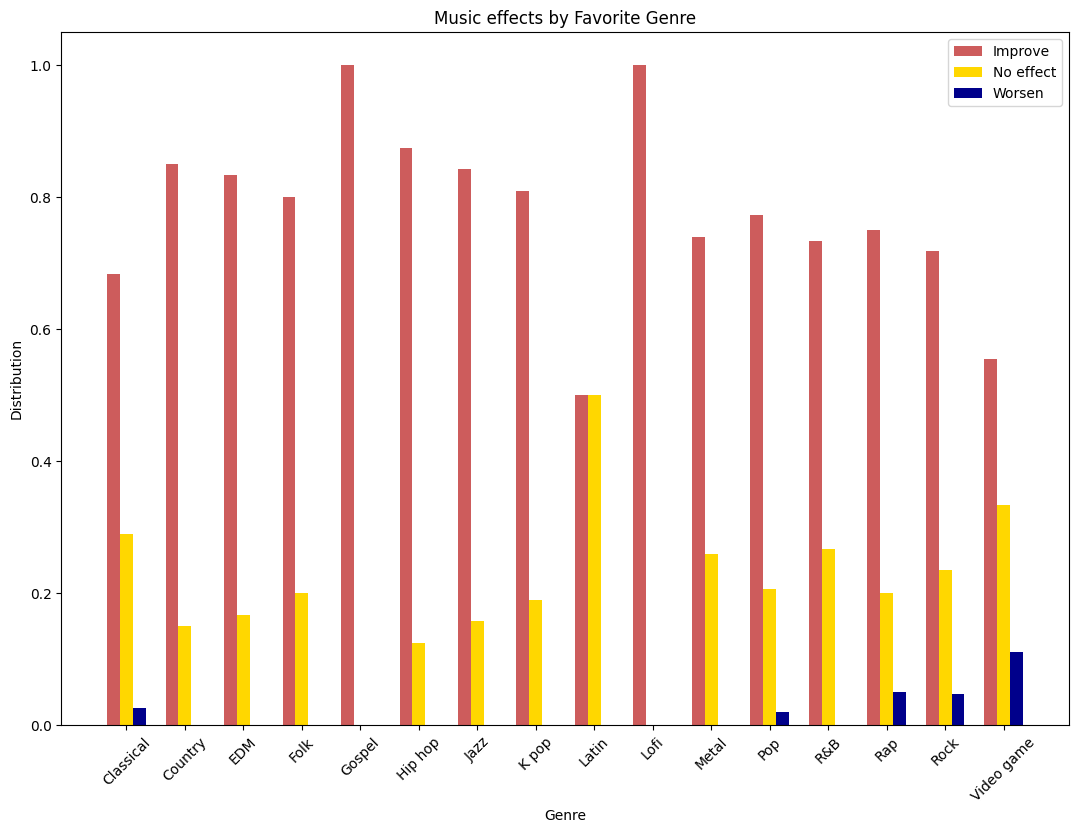

In [25]:
df.replace(['Video game music'],
                       ['Video game'], inplace=True)

g_all = df['Fav genre'].unique()
g_all.sort()
fg_df = df.groupby(['Fav genre'])
fg_dist = fg_df['Music effects'].value_counts(ascending=False, normalize=True).tolist()

insert_indices = [5, 8, 11, 13, 14, 17, 20, 23, 26, 28, 29, 32, 38]
for i in range(len(insert_indices)):
    fg_dist.insert(insert_indices[i], 0)

imp_dist = fg_dist[0::3]
no_eff_dist = fg_dist[1::3]
wors_dist = fg_dist[2::3]

width = 0.22

x = np.arange(len(g_all))

fig, ax = plt.subplots(figsize=(13, 9))

b1 = ax.bar(x-width, imp_dist, width, label="Improve", color = 'indianred')
b2 = ax.bar(x, no_eff_dist, width, label="No effect", color = 'gold')
b3 = ax.bar(x+width, wors_dist, width, label="Worsen", color = 'darkblue')

plt.title("Music effects by Favorite Genre")
ax.set_ylabel('Distribution')
ax.set_xlabel('Genre')
ax.set_xticks(x, g_all, rotation = 45)
ax.legend()

plt.show()

- Regardless of genre, the vast majority of respondents agree that music has a positive impact on mental health. This is corroborated by the "Effects of Music on Mental Health" figure.
- Individuals who selected Gospel and Lofi as their favorite genre unanimously find music beneficial.
- Individuals who selected Video Game Music as their favorite genre have the most diverse distribution of responses. Roughly 40% of these respondents did not find music beneficial at all,  with 10% of respondents reporting a negative impact on their mental health.
- The only other respondents that found music detrimental were respondents who selected Classical, Pop, Rap, or Rock music as their top genre.



        {
            "cell_type": "code",
            "id": "#VSC-9b7ef85b",
            "metadata": {
                "language": "python"
            },
            "source": [
                "# compute average hours listened for respondents with extreme (9-10) MH rankings",
                "anxiety_extreme = df.loc[df['Anxiety'] > 8, 'Hours per day'].mean()",
                "depression_extreme = df.loc[df['Depression'] > 8, 'Hours per day'].mean()",
                "insomnia_extreme = df.loc[df['Insomnia'] > 8, 'Hours per day'].mean()",
                "ocd_extreme = df.loc[df['OCD'] > 8, 'Hours per day'].mean()",
                "",
                "extreme_means = [anxiety_extreme, depression_extreme, insomnia_extreme, ocd_extreme]",
                "",
                "plt.barh(m_all, extreme_means, color=('lightpink', 'cornflowerblue', 'darkmagenta', 'orange'))",
                "plt.xlabel(\"Avg hours listened\")",
                "plt.title(\"Hours listened for individuals with extreme MH rankings\")",
                "plt.xlim(3,5.5)",
                "plt.show()",
                ""
            ]
        },
)

plt.xticks(rotation = 45)
plt.title('Genre vs BPM')
plt.ylim(50, 210)
plt.show()

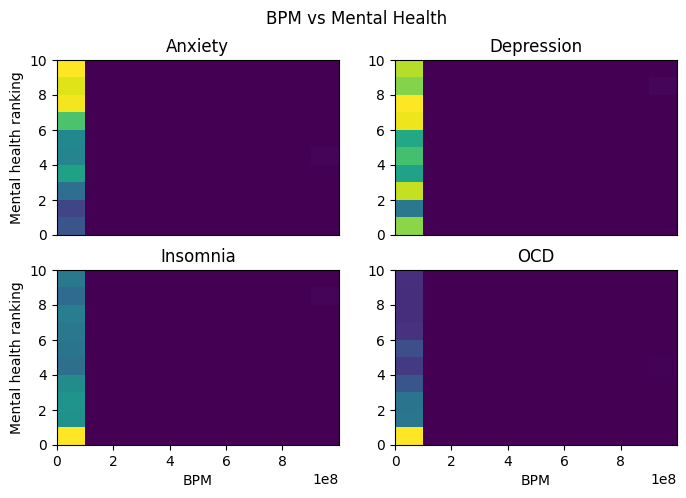

In [26]:
fig = plt.figure(figsize=(8, 5))

plt.suptitle("BPM vs Mental Health")

y = df["Anxiety"]
y2 = df["Depression"]
y3 = df["Insomnia"]
y4 = df["OCD"]
x = df["BPM"]

ax = fig.add_subplot(221)
plt.title('Anxiety')
plt.xticks([])
plt.ylabel('Mental health ranking')
plt.hist2d(x,y, density = True);


ax = fig.add_subplot(222)
plt.title('Depression')
plt.xticks([])
plt.hist2d(x,y2, density = True);

ax = fig.add_subplot(223)
plt.title('Insomnia')
plt.ylabel('Mental health ranking')
plt.xlabel('BPM')
plt.hist2d(x,y3, density = True);

ax = fig.add_subplot(224)
plt.title('OCD')
plt.xlabel('BPM')
plt.hist2d(x,y4, density = True);

In [27]:
df['MH Score'] = df['Anxiety'] + df['Depression'] + df['Insomnia'] + df['OCD']

In [28]:
df.nsmallest(50, ['MH Score'])['BPM'].mean()

np.float64(123.22)

In [29]:
df.nlargest(50, ['MH Score'])['BPM'].mean()

np.float64(117.82)

There is no clear correlation between BPM and mental health rankings.

### Genres

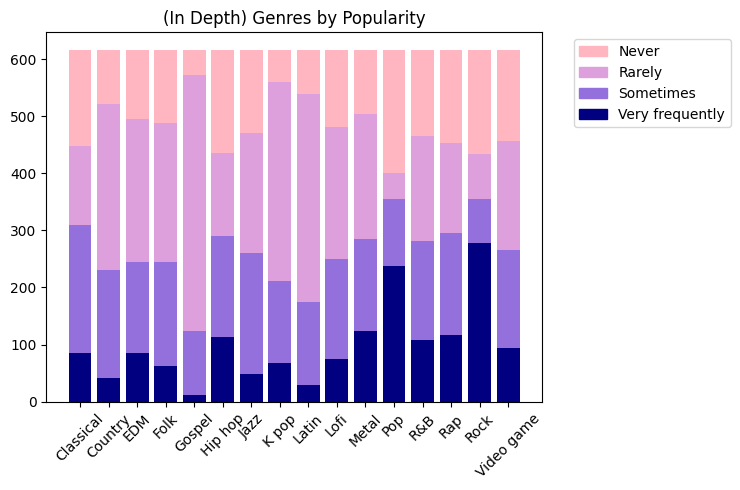

In [30]:
import matplotlib.patches as mpatches

i = 11

r_dist = []
s_dist = []
n_dist = []
vf_dist = []

while i != 27:
    freq_dist = df.iloc[:, i].value_counts().sort_index(ascending=True).tolist()
    r_dist.append(freq_dist[0])
    s_dist.append(freq_dist[1])
    n_dist.append(freq_dist[2])
    vf_dist.append(freq_dist[3])  
    
    i+=1

fig, ax = plt.subplots()

for i in range (0, 16):
    ax.bar(i, r_dist[i], label='Rare', bottom = vf_dist[i] + s_dist[i], color = "plum")
    ax.bar(i, s_dist[i], label='Sometimes', bottom = vf_dist[i], color = "mediumpurple")
    ax.bar(i, n_dist[i], label='Never', bottom=vf_dist[i] + s_dist[i] + r_dist[i], color = "lightpink")
    ax.bar(i, vf_dist[i], label='Very frequently', color = "navy")

ax.set_title('(In Depth) Genres by Popularity')
ax.set_xticks([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15])
ax.set_xticklabels(g_all)
plt.xticks(rotation = 45)

patch1 = mpatches.Patch(color='lightpink', label='Never')
patch2 = mpatches.Patch(color='plum', label='Rarely')
patch3 = mpatches.Patch(color='mediumpurple', label='Sometimes')
patch4 = mpatches.Patch(color='navy', label='Very frequently')

plt.legend(handles=[patch1, patch2, patch3, patch4], bbox_to_anchor=(1.05, 1.0), loc='upper left');

In [31]:
import itertools

med_list = []
med_list2 = []
med_list3 = []
med_list4 = []

df.replace(['Never', 'Rarely', 'Sometimes', 'Very frequently'],
                        [0, 1, 2, 3], inplace=True)

for i in range (11, 27):
    freq_genre = df.columns[i]
    med_list.append(pd.pivot_table(df, values='Anxiety', index=freq_genre, aggfunc="median").values.tolist())
    med_list2.append(pd.pivot_table(df, values='Depression', index=freq_genre, aggfunc="median").values.tolist())
    med_list3.append(pd.pivot_table(df, values='Insomnia', index=freq_genre, aggfunc="median").values.tolist())
    med_list4.append(pd.pivot_table(df, values='OCD', index=freq_genre, aggfunc="median").values.tolist())

def m_vs_gfreq(mlist, fig_name, bd1, bd2):

    r_dist = []
    s_dist = []
    n_dist = []
    vf_dist = []

    for i in range (0, 16):
        n_dist.append(mlist[i][0])
        r_dist.append(mlist[i][1])  
        s_dist.append(mlist[i][2])  
        vf_dist.append(mlist[i][3])  

    labels = g_all
    x = np.arange(len(labels))
    width = 0.15

    fig, ax = plt.subplots(figsize=(10, 4))

    b1 = ax.bar(x-2*width, list(itertools.chain(*n_dist)), width, label="Never", color = 'lightpink')
    b2 = ax.bar(x-width, list(itertools.chain(*r_dist)), width, label="Rarely", color = 'plum')
    b3 = ax.bar(x, list(itertools.chain(*s_dist)), width, label="Sometimes", color = 'mediumpurple')
    b4 = ax.bar(x+width, list(itertools.chain(*vf_dist)), width, label="Very Frequently", color = 'navy')

    ax.set_ylim(bd1, bd2)
    ax.set_ylabel('Ranking')
    ax.set_title(fig_name)
    ax.set_xticks(x, labels)
    ax.legend(loc='upper left')

    plt.xticks(rotation = 45)
    plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_32876\2484853109.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(['Never', 'Rarely', 'Sometimes', 'Very frequently'],


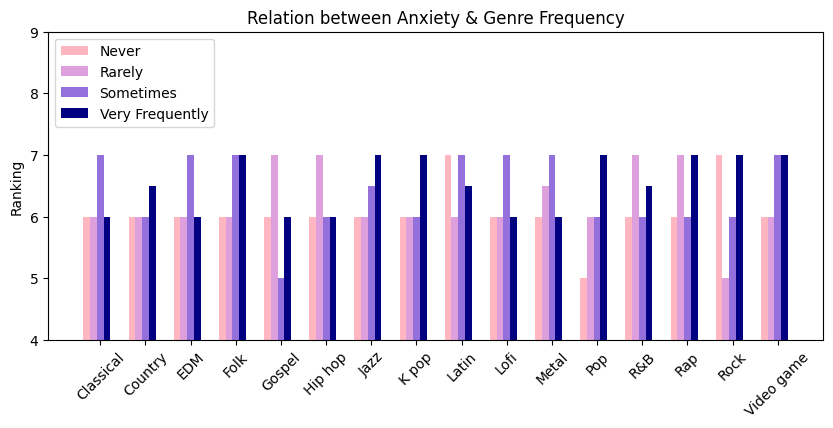

In [32]:
m_vs_gfreq(med_list, 'Relation between Anxiety & Genre Frequency', 4, 9)

- For most genres, a consistent relationship is absent or negligible.
- Very frequently listening to Country music correlates with a slightly higher anxiety ranking.
- Never listening to Folk music with a slightly lower anxiety ranking.
- The most consistent relationship is between anxiety and Pop frequency. As the frequency increases, so do anxiety rankings.
- For respondents who selected "Sometimes" or "Very Frequently" for EDM, Jazz, or Video game music, respondents also reported a higher anxiety ranking than those that selected "Rarely" or "Never."



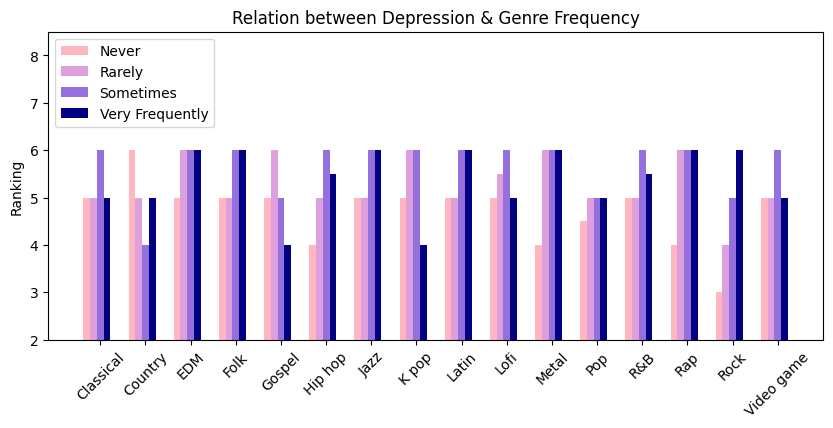

In [33]:
m_vs_gfreq(med_list2, 'Relation between Depression & Genre Frequency', 2, 8.5)

- For most genres, a consistent relationship is absent or negligible.
- Very frequently listening to Gospel music correlates with lower depression rankings.
- Never listening to EDM, Hip hop, Metal, Rap, Rock, or Pop correlates with slightly lower depression rankings.
- The most consistent relationships are between Rock frequency vs depression and R&B vs depression. In both cases, as the frequency increases, so do the depression rankings.

Let's plot Rock individually to visualize this:

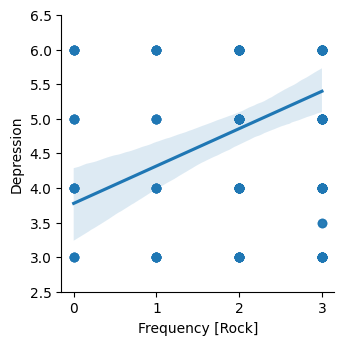

In [34]:
fig = sns.lmplot(x ='Frequency [Rock]', y ='Depression', data = df, height=3.5)
fig.set(ylim=(2.5, 6.5))

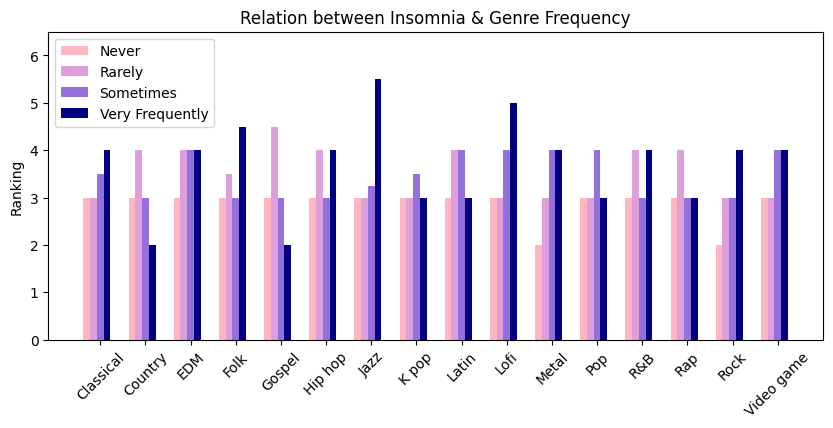

In [35]:
m_vs_gfreq(med_list3, 'Relation between Insomnia & Genre Frequency', 0, 6.5)

- For most genres, a consistent relationship is absent or negligible.
- Very frequent listeners of Country and Gospel music reported lower insomnia rankings.
- This is the opposite case for Metal, Lofi, Jazz,  Rock, and, less apparently, K Pop. For these genres, higher frequencies correlated with higher insomnia rankings.
- Very frequent listeners of Folk, Jazz, and Lofi reported the highest insomnia rankings.

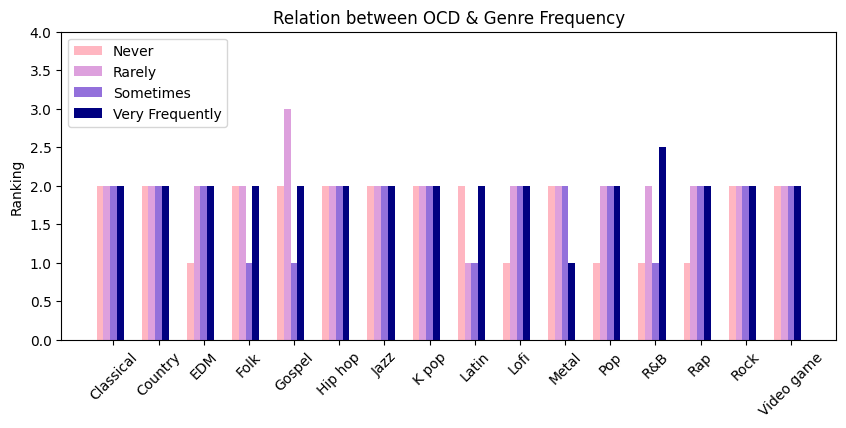

In [36]:
m_vs_gfreq(med_list4, 'Relation between OCD & Genre Frequency', 0,4)

- For most genres, a consistent relationship is absent or negligible.
- Very frequently listening to R&B correlates with a higher OCD ranking.

In [37]:
print('Favorite genres of highest combined MH scorers:')
df.nlargest(60, ['MH Score'])['Fav genre'].value_counts()

Favorite genres of highest combined MH scorers:


Fav genre
Rock          14
Metal          9
Pop            9
EDM            6
Classical      4
Folk           3
Video game     3
R&B            3
Lofi           3
Jazz           2
K pop          1
Hip hop        1
Gospel         1
Rap            1
Name: count, dtype: int64

In [38]:
print('Favorite genres of lowest combined MH scorers:')
df.nsmallest(60, ['MH Score'])['Fav genre'].value_counts()

Favorite genres of lowest combined MH scorers:


Fav genre
Rock          12
Metal          9
Pop            9
Classical      6
EDM            4
Rap            4
R&B            4
Country        4
Jazz           3
K pop          2
Folk           1
Video game     1
Gospel         1
Name: count, dtype: int64

Take note of the overall genre popularity, as outlined in the "Top genre breakdown" figure. Higher value counts for genres such as Rock, Pop, and Metal should be expected.

Considering that Latin and Gospel music accounted for a very small portion of reported favorite genres, it is noteworthy that both of these genres appear in the second list. This suggests that Latin and Gospel music may have a significant correlation with lower MH scores. This is somewhat corroborated by plots generated by the m_vs_gfreq function.

(Of course, the diminished population of Latin and Gospel music lovers means these results are more susceptible to noise.)

Country and Rap also appear more frequently for the lowest MH scorers.

On the other hand, EDM appears slightly more frequently for the highest MH scorers, which is expected as listening to EDM more frequently generally leads to higher MH scores in all categories.

It is further of interest to note that Lofi does not appear in the second list, but appears 3 times in the first. As outlined in the "Relation between Insomnia & Genre Frequency" figure, Lofi enjoyers tended to suffer more from insomnia which may explain this finding.


**Surprising results**

While it is recognized that Rock is the most popular genre, its above value counts are surprising. According to the m_vs_gfreg plots, avid Rock listeners have higher rankings for both Insomnia and Depression. Still, Rock has comparable value counts in both lists.

Similarly, listening to Jazz very frequently pointed towards higher rankings for Anxiety, Depression, and especially Insomnia. Yet, Jazz appears in both lists with similar value counts.

# Conclusions
There are numerous small patterns between music taste and mental health. However, some factors (such as BPM), do not play a significant role. Individual genres also have varying degrees of influence, which is dependent on the MH category. For example, the frequency that an individual listens to Rock is more related to Depression rankings than the frequency for Lofi. However, Lofi is related to higher Insomnia rankings.

Thus, it would be inaccurate to deem one genre to be the "most dangerous."

However, Folk music was the favorite genre for the top combined MH scorer. (Take this with a grain of salt, as a single instance does not generalize to the whole dataset.)

In [39]:
df.nlargest(1, ['MH Score'])['Fav genre']

639    Metal
Name: Fav genre, dtype: object

3. REGRESSION MODELING

In [40]:

# Regression Modeling: Music and Mental Health


from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [46]:
# Combined mental-health score
mh_columns = ['Anxiety', 'Depression', 'Insomnia', 'OCD']
df['MH Score'] = df[mh_columns].sum(axis=1)

# Select numeric predictors only.
numeric_df = df.select_dtypes(include=np.number)

# Exclude the score and its components to prevent target leakage.
excluded_columns = mh_columns + ['MH Score']
feature_columns = [
    col for col in numeric_df.columns
    if col not in excluded_columns
]

X = numeric_df[feature_columns].copy()
y = df['MH Score'].copy()

In [47]:
# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Remove predictors that contain no usable values
X = X.dropna(axis=1, how='all')

# Remove constant predictors
X = X.loc[:, X.nunique(dropna=True) > 1]

print("Number of observations:", len(X))
print("Number of predictors:", X.shape[1])
print("Predictors used:")
print(X.columns.tolist())

# Split before fitting preprocessing or models
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

Number of observations: 616
Number of predictors: 24
Predictors used:
['Age', 'Hours per day', 'While working', 'Instrumentalist', 'Composer', 'Exploratory', 'Foreign languages', 'BPM', 'Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]', 'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]', 'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]', 'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]', 'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]', 'Frequency [Video game music]']


In [57]:
#Train Ridge, Lasso, PLS and PCR
import pandas as pd

# Set up cross-validation using training data only
cv = KFold(n_splits=5, shuffle=True, random_state=42)

max_components = min(10, X_train.shape[1], len(X_train) - 1)

# Shared preprocessing
def make_preprocessor():
    return [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]

models = {
    'Ridge Regression': (
        Pipeline(make_preprocessor() + [
            ('model', Ridge())
        ]),
        {'model__alpha': [0.01, 0.1, 1, 10, 100]}
    ),

    'Lasso Regression': (
        Pipeline(make_preprocessor() + [
            ('model', Lasso(max_iter=20000))
        ]),
        {'model__alpha': [0.001, 0.01, 0.1, 1, 10]}
    ),

    'PLS Regression': (
        Pipeline(make_preprocessor() + [
            ('model', PLSRegression())
        ]),
        {'model__n_components': list(range(1, max_components + 1))}
    ),

    'PCR': (
        Pipeline(make_preprocessor() + [
            ('pca', PCA()),
            ('model', LinearRegression())
        ]),
        {'pca__n_components': list(range(1, max_components + 1))}
    )
}

results = []
fitted_models = {}
predictions = {}

for name, (pipeline, parameters) in models.items():

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring='r2',
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    y_pred = np.asarray(best_model.predict(X_test)).reshape(-1)

    fitted_models[name] = best_model
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'CV R2': search.best_score_,
        'Test R2': r2_score(y_test, y_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'Test MAE': mean_absolute_error(y_test, y_pred),
        'Best Parameters': search.best_params_
    })

results_df = pd.DataFrame(results).sort_values(
    by='Test R2', ascending=False
).reset_index(drop=True)

results_df.round(4)



,Model,CV R2,Test R2,Test RMSE,Test MAE,Best Parameters
0,Ridge Regression,-1.986802e+09,0.0203,7.3501,5.9799,{'model__alpha': 100}
1,PLS Regression,-8.529510e+08,0.0144,7.3723,6.0432,{'model__n_components': 1}
2,PCR,-1.352730e+07,0.0011,7.4216,6.2021,{'pca__n_components': 1}
3,Lasso Regression,-6.000000e-04,0.0004,7.4242,6.2208,{'model__alpha': 1}


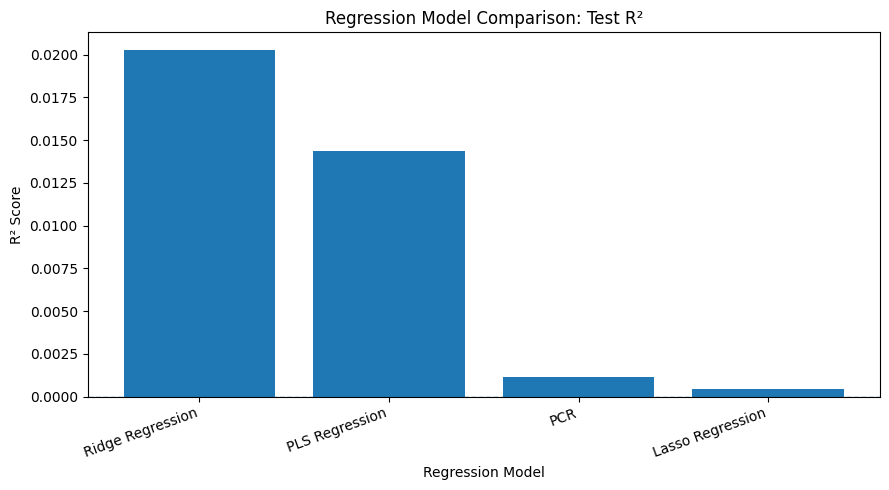

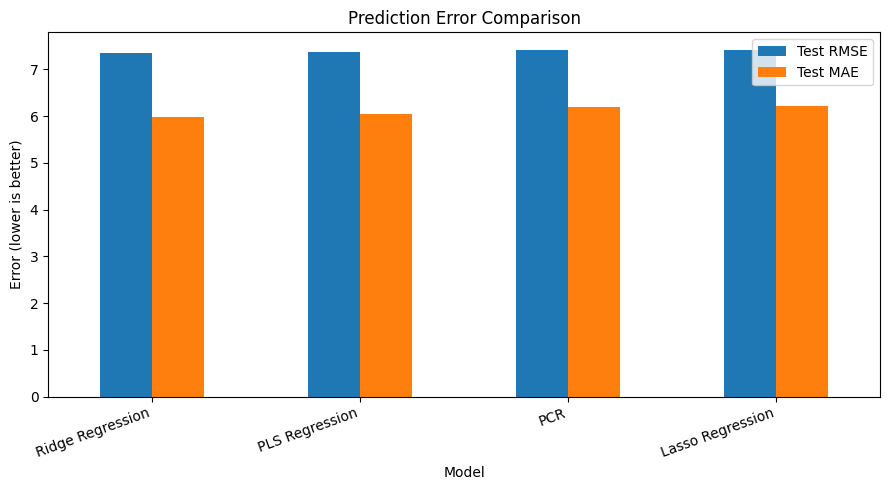

In [58]:
# Visualize the Comparison of Model Performance

# Compare test-set R² scores
plt.figure(figsize=(9, 5))

plt.bar(results_df['Model'], results_df['Test R2'])
plt.axhline(0, linestyle='--', linewidth=1)

plt.title('Regression Model Comparison: Test R²')
plt.xlabel('Regression Model')
plt.ylabel('R² Score')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

# Compare prediction errors
error_columns = ['Test RMSE', 'Test MAE']

results_df.set_index('Model')[error_columns].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Prediction Error Comparison')
plt.ylabel('Error (lower is better)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()


In [59]:
# Conclusion 

# Identify the best model using test R²
best_row = results_df.loc[results_df['Test R2'].idxmax()]
best_name = best_row['Model']

print("REGRESSION MODEL CONCLUSION")
print("=" * 50)

print(f"Best model by test R²: {best_name}")
print(f"Test R²: {best_row['Test R2']:.4f}")
print(f"Test RMSE: {best_row['Test RMSE']:.4f}")
print(f"Test MAE: {best_row['Test MAE']:.4f}")

if best_row['Test R2'] > 0:
    print(
        "\nThe best model explains approximately "
        f"{best_row['Test R2'] * 100:.2f}% of the variation "
        "in the combined mental-health score on the test set."
    )
else:
    print(
        "\nThe best model does not outperform predicting "
        "the test-set mean according to R²."
    )

if best_row['Test R2'] < 0.10:
    print(
        "Predictive performance is weak. The available numeric "
        "music-related variables explain little of the variation "
        "in the combined score."
    )
elif best_row['Test R2'] < 0.50:
    print(
        "Predictive performance is limited to moderate. "
        "Important variation in the score remains unexplained."
    )
else:
    print(
        "The model shows meaningful predictive performance "
        "on this test split. Further validation is needed."
    )

print(
    "\nThese results describe prediction, not causation. "
    "They do not establish that music preferences cause "
    "changes in mental health."
)


REGRESSION MODEL CONCLUSION
Best model by test R²: Ridge Regression
Test R²: 0.0203
Test RMSE: 7.3501
Test MAE: 5.9799

The best model explains approximately 2.03% of the variation in the combined mental-health score on the test set.
Predictive performance is weak. The available numeric music-related variables explain little of the variation in the combined score.

These results describe prediction, not causation. They do not establish that music preferences cause changes in mental health.


In [60]:
# which variable affect lasso

lasso_model = fitted_models['Lasso Regression']
lasso_coefficients = lasso_model.named_steps['model'].coef_

lasso_features = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lasso_coefficients
})

lasso_features['Absolute Coefficient'] = (
    lasso_features['Coefficient'].abs()
)

lasso_features = lasso_features.sort_values(
    'Absolute Coefficient', ascending=False
)

print("Lasso feature coefficients:")
display(lasso_features.round(4))

print("\nPredictors with nonzero coefficients:")
display(
    lasso_features.loc[
        lasso_features['Coefficient'].abs() > 1e-8,
        ['Feature', 'Coefficient']
    ]
)


Lasso feature coefficients:


,Feature,Coefficient,Absolute Coefficient
0,Age,-0.1068,0.1068
10,Frequency [EDM],0.0523,0.0523
18,Frequency [Metal],0.0483,0.0483
1,Hours per day,0.0000,0.0000
4,Composer,0.0000,0.0000
5,Exploratory,0.0000,0.0000
2,While working,0.0000,0.0000
3,Instrumentalist,0.0000,0.0000
7,BPM,0.0000,0.0000
6,Foreign languages,0.0000,0.0000



Predictors with nonzero coefficients:


,Feature,Coefficient
0,Age,-0.106833
10,Frequency [EDM],0.052326
18,Frequency [Metal],0.048327


### Regression Analysis: Music and Mental Health

Four regression approaches—Ridge Regression, Lasso Regression, Partial Least Squares (PLS) Regression, and Principal Component Regression (PCR)—were evaluated to investigate whether the available numerical variables could predict the combined mental-health score of survey respondents.

Among the evaluated models, Ridge Regression achieved the highest test-set coefficient of determination (\(R^2 = 0.0203\)), with a root mean squared error (RMSE) of 7.3501 and a mean absolute error (MAE) of 5.9799. The test \(R^2\) indicates that the model explained approximately 2.03% of the variation in the combined mental-health score. This suggests that the numerical predictors included in the current analysis have limited predictive power.

These findings do not establish that music preferences or listening habits have no relationship with mental health. Rather, they indicate that the variables and modeling approach used in this analysis are insufficient to predict the combined score accurately. Other factors, measurement limitations, nonlinear relationships, and the exclusion of categorical variables may contribute to the weak predictive performance.

Further analysis should investigate categorical music preferences and listening habits, assess individual mental-health outcomes separately, and evaluate the models using robust validation procedures. The findings should be interpreted as associations and predictive results rather than evidence of causal relationships between music and mental health.